# **STEP 2, PART 1.2**
### **LAB preparation for zero level removal and noise profiling**

This notebook is run **once** (again only if the LAB treatment changes). It measures the empty channels (steps 1-2b), checks the zero level of the two telescopes (steps 3-8), decides which cube is the LAB cube, measures sigma **on that cube** (steps 9-10) and stores everything in `lab_products.npz`. Every other notebook then starts with

```python
from mw_io import load_lab_products
lab, l_lab, b_lab, v_lab, P = load_lab_products("lab_products.npz")
# P.sigma_empty, P.sigma_null, P.sigma_map, P.use_cmp, ...
```

and inherits the cube and its sigma. Thereby, we repeat nothing, and a notebook cannot use a sigma that belongs to another cube.

Two switches decide what the stored cube is: `REPAIR_HOT` (add back the over-subtracted offsets of the hot pixels, in step 3b) and `APPLY_PROFILE` (subtract a zero-level profile per telescope, in step 6b). Without both, it is the cube of `load_lab_clean`, which is what all earlier runs used.

In [1]:
import sys, time, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

from mw_io import load_fits, load_npz, load_lab_clean, load_lab_products, save_lab_products, save_correction
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions,
                     flat_v_circ, OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)

from marasco_comp import *
from sigma_comp import *
import lab_background as bkg

LAB_PATH = "../Displays/lab.fit.gz"
GRID = Path("./grid")                   # the grid-search cubes (f_ion probes, stage Q/B ...)
CONV = Path("./conv")                   # the convergence-study cubes (tiers 1-4)
B_CUT = 0
L_CUT = 0
V_DEV = 35.0                            # km/s: |v_dev| below this is disc (Marasco+12 sect. 2.4: 35)
REL_FLOOR = 0.04                        # K: softening of the relative residual (see the module docstring)
N_REF = 40                              # n_per_bin of the convergence reference group
HV_STEP = 5.0                           # km/s between the N and D groups of the convergence study (60 -> 65)

cfg = CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0)       # Marasco+12: everything smoothed to 8 degrees

PRODUCTS = "lab_products.npz"
CORR_PATH = "lab_background_correction.npz"

### LAB data

In [2]:
lab, l_lab, b_lab, v_lab = load_lab_clean(LAB_PATH)
ax_lab = (l_lab, b_lab, v_lab)

> Seam columns differ by at most 4.5024986 K


## 1. Empty channels at native resolution
`load_lab_clean` subtracts, in every sky pixel, the median of the empty channels (-400..-300 and +300..+390 km/s).

But here, the raw empty channels are read again to see what that offset looks like and whether removing a constant is justified, because that is what we assumed before. So, let's check:

* **Offset map and distribution:** How large is it against the noise? Where is it?
* **Constant in velocity:** The offset from the negative $v$ range and from the positive $v$ range must agree within the noise. The width of their difference is compared with the width expected for a flat baseline (ratio ~ 1). If this is much larger, then the baseline changes with velocity and a constant is not enough of an approximation.
* **Sky-averaged spectrum:** The empty channels after the offset is removed should have no trend with $v$.
* **Histogram of (value - offset)/sigma_pixel:** The negative tail cannot be emission, so it is the false-detection rate of a k-sigma contour; a positive excess over the negative tail is real emission (or skew) in the empty channels.

Empty channels: 97 + 87 (native channel width 1.03 km/s)
Offset: median background over the sky +0.000e+00 mK, robust width 5.6 mK (mean-vs-median rms 14.5 mK)
Offset constant in v?  observed / expected width of (positive range - negative range) = 0.83   (1 = flat)
Sigma (median) per pixel, native: 72.3 mK
   The tail beyond 2 sigma:  positive 2.476%   negative 2.370%   Gaussian 2.275% each
   The tail beyond 3 sigma:  positive 0.229%   negative 0.175%   Gaussian 0.135% each


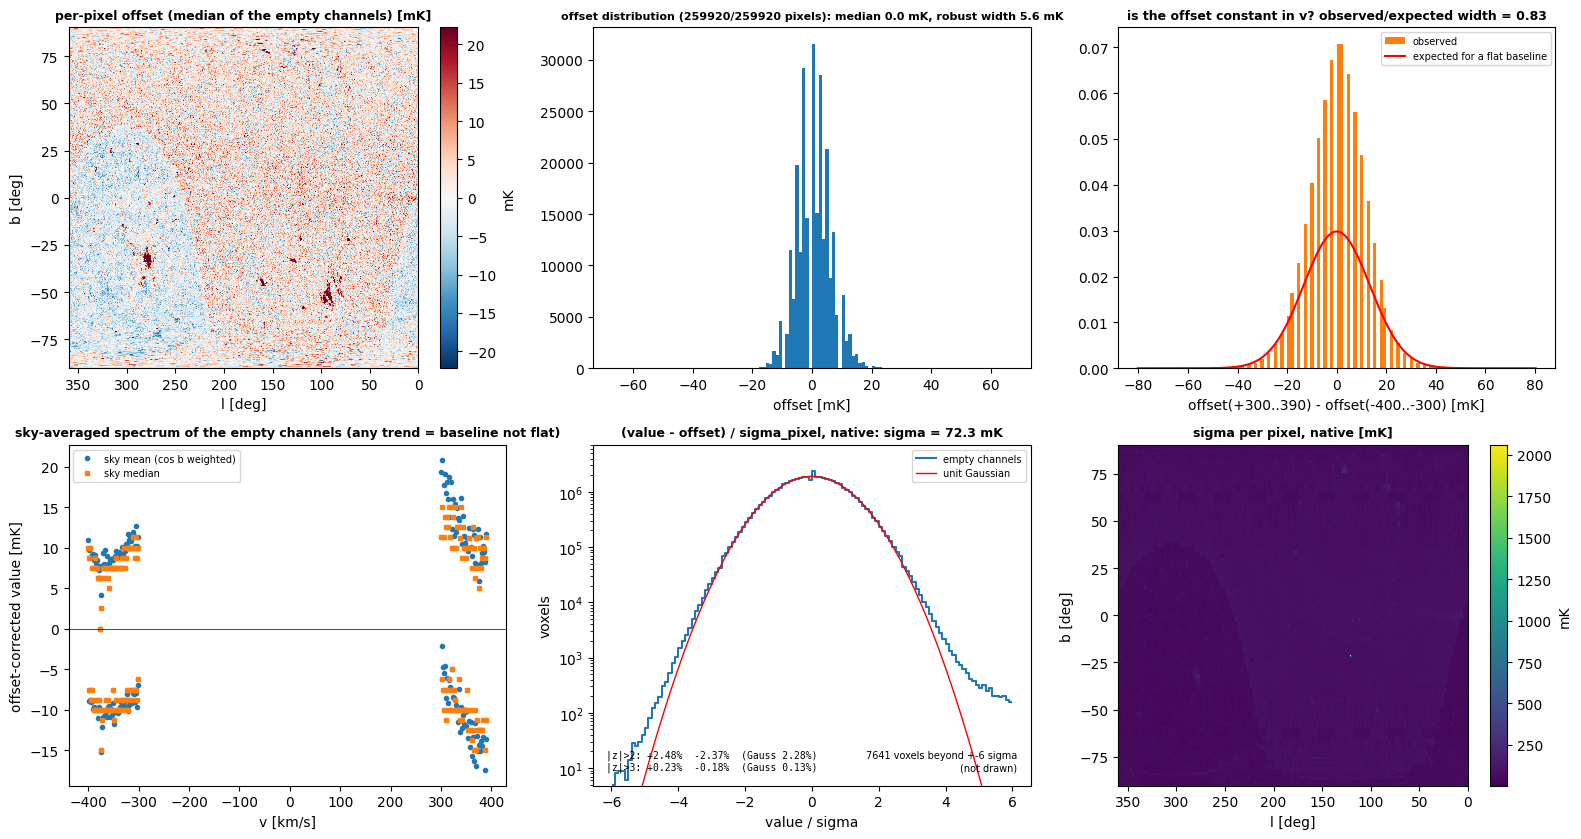

In [3]:
E, l_e, b_e, v_e = load_empty_channels(LAB_PATH, load_fits, NOISE_RANGES)
nat = native_noise_report(E, v_e, l_e, b_e)

print(f"Empty channels: {nat['n_per_range'][0]} + {nat['n_per_range'][1]} "
      f"(native channel width {abs(np.median(np.diff(v_e))):.2f} km/s)")
print(f"Offset: median background over the sky {nat['offset_median']*1e3:+.3e} mK, "
      f"robust width {nat['offset_rms']*1e3:.1f} mK (mean-vs-median rms {nat['mean_minus_median_rms']*1e3:.1f} mK)")
print(f"Offset constant in v?  "
      f"observed / expected width of (positive range - negative range) = {nat['baseline_excess']:.2f}   (1 = flat)")
print(f"Sigma (median) per pixel, native: {nat['sigma_native']*1e3:.1f} mK")

for k, t in nat["tails"].items():
    print(f"   The tail beyond {k:g} sigma:  positive {100*t['pos']:.3f}%   negative {100*t['neg']:.3f}%   "
          f"Gaussian {100*t['gauss']:.3f}% each")

plot_native_noise(nat)
plt.show()

## 2. The same channels after the comparison pipeline

Now, we rebin to 8 km/s, smooth to $8^\circ$ with the beam convolution, but no mask. The background offset is measured again because it was a median per native pixel, so it is not guaranteed to be zero and a baseline that varies with velocity shows up here as a non-zero offset at the smoothed scale. 

Sigma is measured twice: **about zero** (what a line channel sees if nothing more is subtracted) and **about the per-pixel offset** (if it is subtracted).

23 empty comparison channels of 8 km/s
Sigma about zero: 3.76 mK     about the per-pixel offset: 3.69 mK     native: 72.3 mK  (ratio smoothed/native = 0.052)
Offset map (background) after smoothing: robust width 0.65 mK; expected from the noise alone 0.98 mK  ->  0.17 sigma
Offset constant in v?  observed / expected = 1.20
Sigma by |b| bin [mK]: 0-10: 4.27  10-20: 3.89  20-30: 3.74  30-45: 3.47  45-60: 3.71  60-80: 3.70
   The tail beyond 2 sigma (about zero):  positive 3.221%   negative 2.856%   Gaussian 2.275% each
   The tail beyond 3 sigma (about zero):  positive 0.911%   negative 0.566%   Gaussian 0.135% each


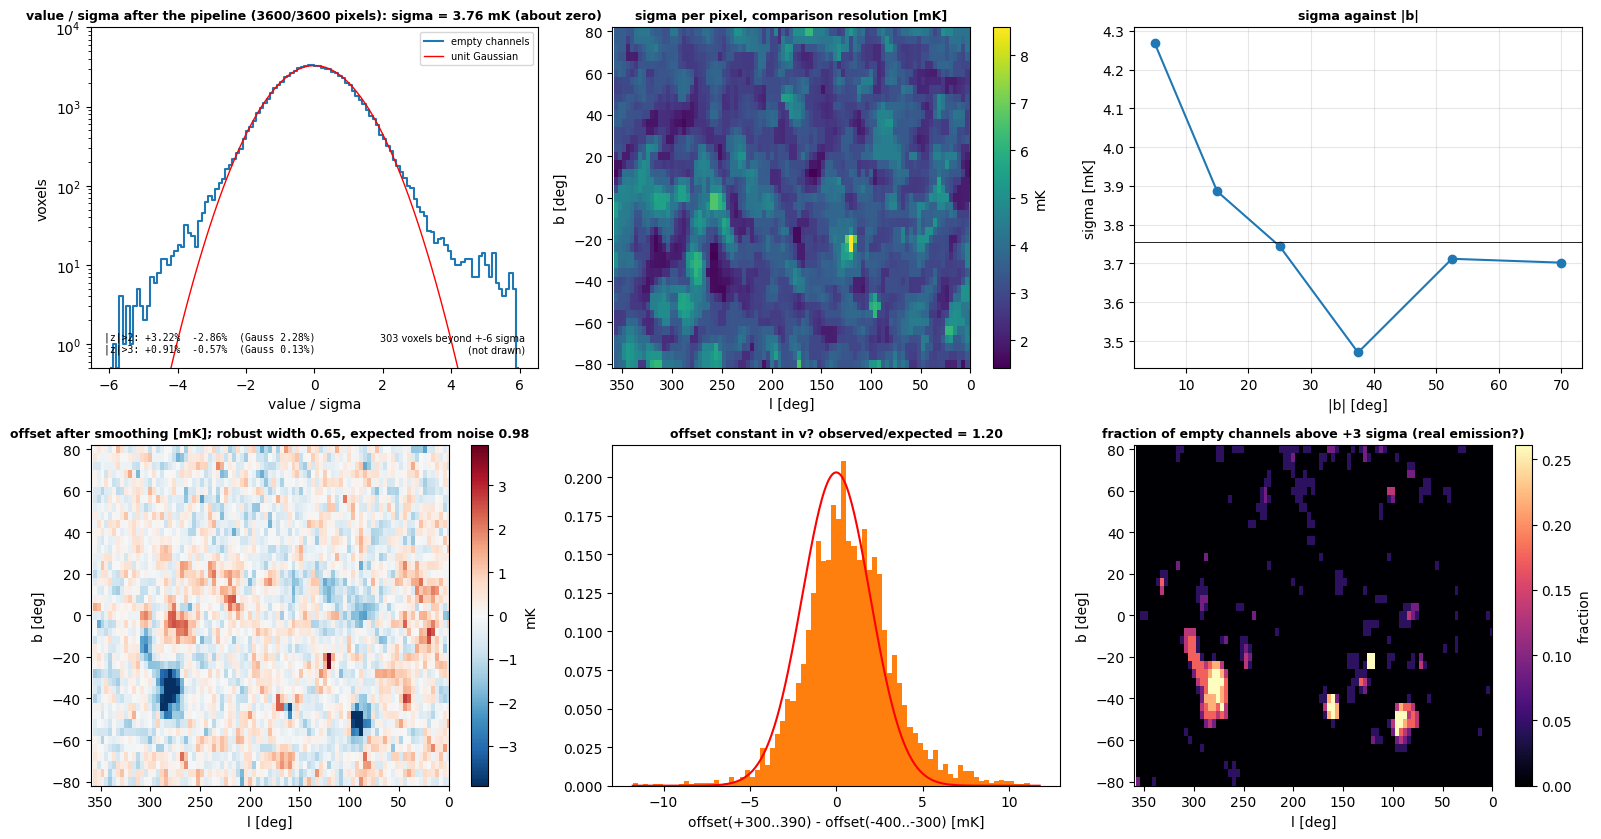

In [4]:
sm = smoothed_noise_report(lab, ax_lab, cfg)

print(f"{sm['n_ch']} empty comparison channels of {cfg.dv:g} km/s")
print(f"Sigma about zero: {sm['sigma0']*1e3:.2f} mK     "
      f"about the per-pixel offset: {sm['sigma_centred']*1e3:.2f} mK     "
      f"native: {nat['sigma_native']*1e3:.1f} mK  (ratio smoothed/native = {sm['sigma0']/nat['sigma_native']:.3f})")
print(f"Offset map (background) after smoothing: robust width {sm['offset_rms']*1e3:.2f} mK; "
      f"expected from the noise alone {sm['offset_expected']*1e3:.2f} mK  ->  {sm['offset_rms']/sm['sigma0']:.2f} sigma")
print(f"Offset constant in v?  observed / expected = {sm['baseline_excess']:.2f}")
print("Sigma by |b| bin [mK]: " + 
      "  ".join(f"{lo:g}-{hi:g}: {s*1e3:.2f}" for lo, hi, s in zip(sm['b_bins'][:-1], sm['b_bins'][1:], sm['sigma_by_b'])))
for k, t in sm["tails"].items():
    print(f"   The tail beyond {k:g} sigma (about zero):  positive {100*t['pos']:.3f}%   negative {100*t['neg']:.3f}%   "
          f"Gaussian {100*t['gauss']:.3f}% each")

SIGMA_EMPTY = sm["sigma0"]

plot_smoothed_noise(sm)
plt.show()

## 2b. Noise on clean pixels only
The 'empty' channels are not empty everywhere. A few places still hold emission or a leftover baseline (for example, M31 near l = 121, b = -22; the Magellanic wing in the first +300 km/s channels at l ~ 270-300, etc.), and |b| > 80 is a sliver of sky that a regular l-b grid over-samples hugely. Both are left out of every **statistic** (sigma, offset width, histograms, tails, baseline); the data themselves are untouched.

* **flagged**: a pixel with at least 2 empty channels above $+3\sigma$, or with a leftover mean offset more than 4 robust widths from the sky median,
* **grown** by one pixel (4 degrees, half the beam), because the 8-degree smoothing spreads emission to its neighbours,
* the **native** statistics use the same pixels (the mask is copied to the native grid); the flags need sigma and sigma needs the flags, so it is done twice.

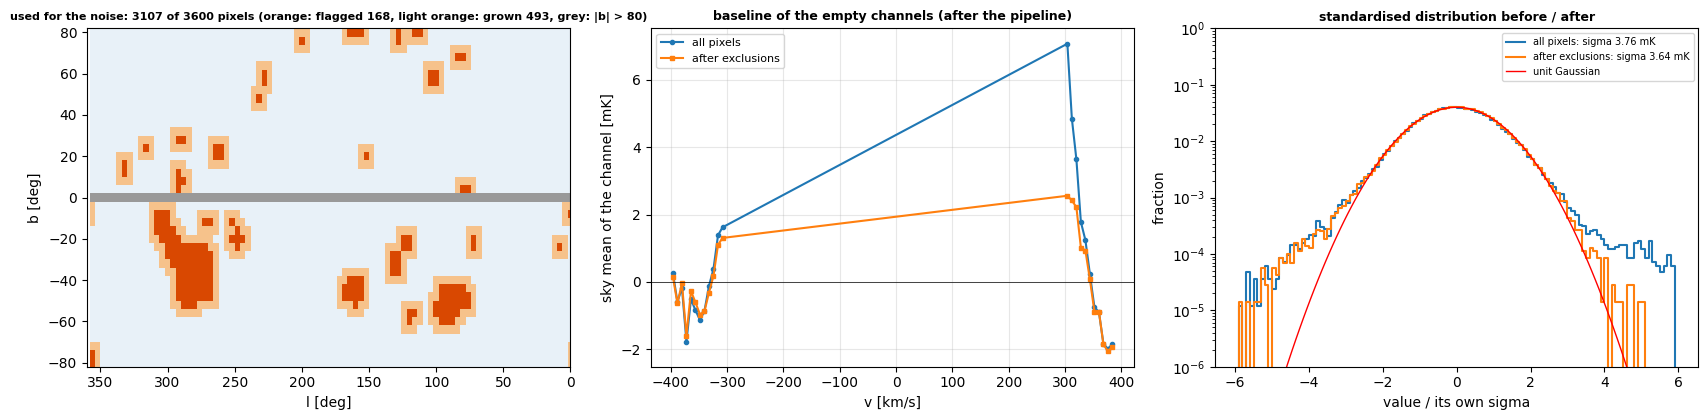

flagged 168 pixels, grown to 493; used 3107 of 3600 compared pixels (|b| > 80 and b = 0 are never used)
                                               all pixels   clean pixels
Pixels used, comparison grid                         3600           3107
Pixels used, native grid                           259920         194360
Sigma, native [mK]                                   72.3           74.1
Sigma, smoothed, about zero [mK]                    3.755          3.635
Sigma, smoothed, about the offset [mK]              3.691          3.595
Offset width after smoothing [mK]                   0.652          0.617
   ... in sigma (a median of n channels: ~0.30)         0.17           0.17
Baseline excess (1 = flat in v)                      1.20           1.15
beyond +2 sigma [%]  (Gauss 2.275)                  3.221          2.481
beyond -2 sigma [%]                                 2.856          2.820
beyond +3 sigma [%]  (Gauss 0.135)                  0.911          0.210
beyond -3 sigma [

In [5]:
USE_EXCLUSIONS = True        # edit: False = every pixel, as in the previous run
FLAG = dict(k=3.0, min_ch=2, mean_k=4.0, dilate=1, bmax=80.0) # dilate is in comparison pixels, 4 deg each.

sm_all, nat_all = sm, nat
SIGMA_EMPTY_ALL = SIGMA_EMPTY
USE_CMP = np.ones(sm_all["S"].shape[1:], bool)

if USE_EXCLUSIONS:
    sm_x = sm_all
    for it in range(2): # The flags need sigma, sigma needs the flags; twice is enough.
        fl = emission_flags(sm_x, **FLAG)
        sm_x = resummarize(sm_all, fl["use"])

    USE_CMP = fl["use"]
    sm = sm_x
    nat = native_noise_report(E, v_e, l_e, b_e, use=regrid_mask(USE_CMP, sm_all["l"], sm_all["b"], l_e, b_e), 
                              bmax=FLAG["bmax"])
    SIGMA_EMPTY = sm["sigma0"]
    plot_exclusions(fl, sm_all, sm); plt.show()
    print(f"flagged {fl['n_hot']} pixels, grown to {fl['n_grown']}; used {fl['n_use']} of {fl['n_rows_pix']} compared pixels (|b| > {FLAG['bmax']:g} and b = 0 are never used)")

def _row(name, a, b, f="{:.2f}"):
    print(f"{name:44s} {f.format(a):>12s} {f.format(b):>14s}")

print(f"{'':44s} {'all pixels':>12s} {'clean pixels':>14s}")
_row("Pixels used, comparison grid", sm_all["n_pix_used"], sm["n_pix_used"], "{:d}")
_row("Pixels used, native grid", nat_all["n_pix_used"], nat["n_pix_used"], "{:d}")
_row("Sigma, native [mK]", nat_all["sigma_native"] * 1e3, nat["sigma_native"] * 1e3, "{:.1f}")
_row("Sigma, smoothed, about zero [mK]", sm_all["sigma0"] * 1e3, sm["sigma0"] * 1e3, "{:.3f}")
_row("Sigma, smoothed, about the offset [mK]", sm_all["sigma_centred"] * 1e3, sm["sigma_centred"] * 1e3, "{:.3f}")
_row("Offset width after smoothing [mK]", sm_all["offset_rms"] * 1e3, sm["offset_rms"] * 1e3, "{:.3f}")
_row("   ... in sigma (a median of n channels: ~0.30)", sm_all["offset_rms"] / sm_all["sigma0"], 
     sm["offset_rms"] / sm["sigma0"], "{:.2f}")
_row("Baseline excess (1 = flat in v)", sm_all["baseline_excess"], sm["baseline_excess"])
for k in sm["tails"]:
    _row(f"beyond +{k:g} sigma [%]  (Gauss {100*sm['tails'][k]['gauss']:.3f})", 100 * sm_all["tails"][k]["pos"], 
         100 * sm["tails"][k]["pos"], "{:.3f}")
    _row(f"beyond -{k:g} sigma [%]", 100 * sm_all["tails"][k]["neg"], 100 * sm["tails"][k]["neg"], "{:.3f}")

first = lambda r: np.round(r["chan_mean"][r["ridx"] == 1][:4] * 1e3, 1)

print(f"Sky mean of the first four +300 km/s channels [mK]:  all {first(sm_all)}   clean {first(sm)}")
print(f"Native offset width [mK]: all {nat_all['offset_rms']*1e3:.2f}   clean {nat['offset_rms']*1e3:.2f}")
print(f"Sigma used from here on: {SIGMA_EMPTY*1e3:.3f} mK  (all pixels: {SIGMA_EMPTY_ALL*1e3:.3f} mK)")

## 3. Zero level per telescope, and throughout the cube

Steps 1-2b measured the background in the empty windows only (-400..-300, +300..+390 km/s), and `load_lab_clean` removed one number per pixel from them. However, this is a simplistic approach to noise for LAB specifically. Two questions are left:

1. **The telescope step:** LAB is two surveys, reduced separately: Dwingeloo (dec > -25 deg) and Villa Elisa (dec < -27 deg), averaged with equal weight in between. Their raw window offsets differ (step 3). The per-pixel median removes this **at the window level**. However, nothing in the windows says that the baseline in the **line** channels has the same level. We clearly see this difference in step 1.
2. **The shape in $v$.** After rebinning, the sky mean of the empty channels is not completely flat, and a constant per pixel cannot remove a shape.

The background is modelled as a smooth function of velocity **per telescope**, $c_N(v)$ and $c_S(v)$. A voxel's background is $w\,c_N + (1-w)\,c_S$ with $w$ the weight of the northern survey. 

Instead of relying only own empty windows, the profiles are measured from the **empty voxels of the whole cube** (the windows, and the empty parts of the channels with emission): a voxel is *not* empty 
- if it is beyond $3\sigma$ from the current background, **or** 
- if the mean over any of ten boxes around it (1x3x3 to 9x9x9 voxels, and 3x15x15) is beyond $3\sigma_\mathrm{box}$ (calibrated on the windows), **or** 
- if it touches such a voxel.

The cuts are two-sided; the finder and profiles are iterated (10 times) to find an appropriate amount of trustworthy empty voxels. The profiles are then smoothed (FWHM 40 km/s) and are constant beyond the last measured channel. 

Errors: a grouped jackknife of the whole chain, inflated by 2.5 and with floors of 0.2 / 0.6 / 1.5 mK (window / measured line channel / interpolated).

**What this can and cannot do:** In the windows, every voxel is empty by definition, so the result there can be checked directly against the plain sky mean (`window_check`, step 2c-6). 

In the **line channels,** a baseline and faint extended emission look the same to any voxel statistic: whatever the finder lets through is attributed to the background. On the real cube, the fitted profile of the Villa Elisa zone in the line channels is several mK, with the sharp edges of an emission feature rather than the smooth shape of a baseline. The Magellanic System and the HVCs fill much of that zone, so it is most likely emission. That is why the profile is **not** subtracted by default. If it is not okay to subtract, we will not do so.

North    raw window offset   +1.74 ± 0.07 mK   (147573 pixels)
Overlap  raw window offset   -0.37 ± 0.13 mK   (3213 pixels)
South    raw window offset   -2.79 ± 0.12 mK   (43574 pixels)
North - south = +4.53 ± 0.14 mK   (33.2 sigma; grouped jackknife, cos b weighted)


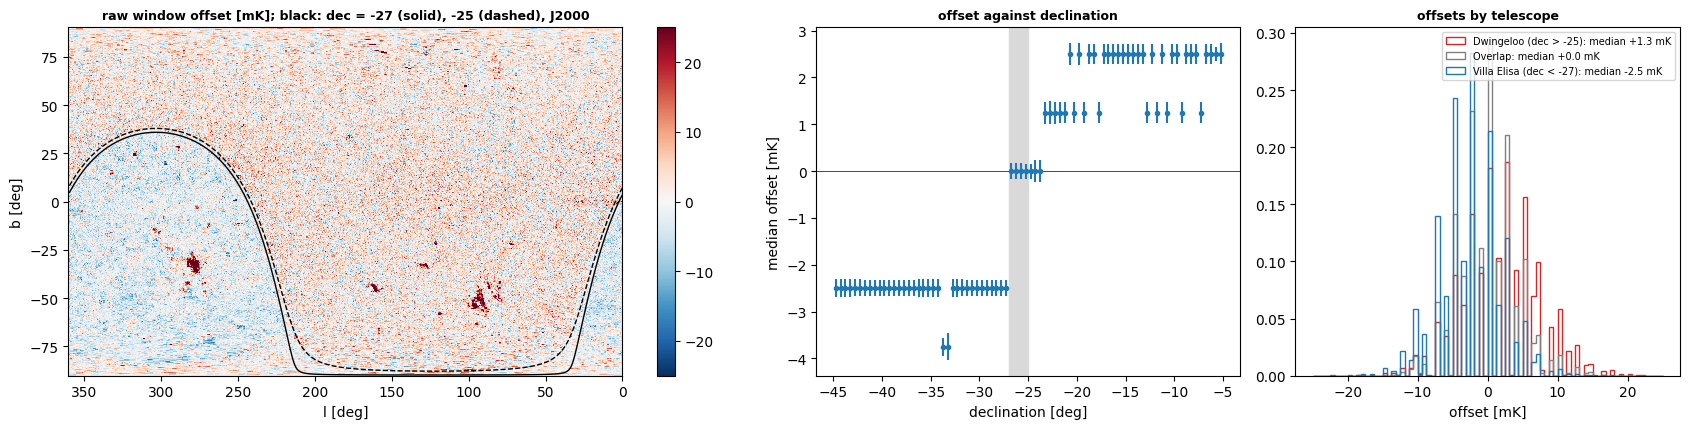

In [6]:
EPOCH = "J2000" # The queries are given in that. I have no reason to believe it would be B1950.
DEC_ARGS = dict(dec_lo=-27.0, dec_hi=-25.0, epoch=EPOCH, shift=0.0) # shift: move both limits (deg), to test the sensitivity.

# Weight of the northern survey (Dwingeloo) in every native pixel: 1 north, 0 south, 0.5 in the overlap strip.
W_NATIVE = bkg.telescope_weight(l_lab, b_lab, **DEC_ARGS)

zo = bkg.zone_offsets(nat["med_map"], W_NATIVE, l_lab, b_lab, use=nat["use"])

for name in ("north", "overlap", "south"):
    m, se, n = zo[name]
    print(f"{name.capitalize():8s} raw window offset {m*1e3:+7.2f} ± {se*1e3:.2f} mK   ({n} pixels)")

d, se, _ = zo["north_minus_south"]
print(f"North - south = {d*1e3:+.2f} ± {se*1e3:.2f} mK   ({abs(d)/se:.1f} sigma; grouped jackknife, cos b weighted)")

bkg.plot_zones(nat["med_map"], l_lab, b_lab, W_NATIVE, EPOCH, use=nat["use"])
plt.show()

### 3b. Hot pixels in the offsets
`load_lab_clean` subtracted the median of the window channels of each pixel. Where the Magellanic System or M31 sits in a window, that median is pulled **up**, so the pixel was over-subtracted in every channel. A single pixel cannot be judged (its median has ~7 mK of noise, more than most excesses), so the offsets are tested in boxes of 3-15 pixels and the excess is added back **smoothly**, only where a box is beyond $4\sigma_\mathrm{box}$ (about one false region on the whole sky; tested on synthetic data). It is partial (about half of the true excess is recovered) and never adds noise to single pixels. Most of these pixels lie in regions that the comparison masks anyway (Magellanic system, M31, other external galaxies).

This is an optional measure that will change how cubes are interpreted afterwards. Currently, due to limited benefit, we elected not to use it.

In [7]:
# True: adds back the over-subtracted offsets of the hot pixels (changes the cube: RES/MODS must then be rebuilt).
REPAIR_HOT = False

if REPAIR_HOT and not globals().get("HOT_DONE", False):
    lab, hot = bkg.repair_hot_offsets(lab, nat["med_map"], W_NATIVE)          # in place
    HOT_DONE = True
    print(f"{hot['n_hot']} pixels in hot regions, largest excess added back {hot['max_excess']*1e3:.1f} mK; "
          f"box widths [mK]: " + ", ".join(f"{k}px {x*1e3:.2f}" for k, x in hot["widths"].items()))
    HOT_EXCESS = hot["excess"]
else:
    HOT_EXCESS = None

### 4. The empty voxels and the profiles
Everything below works on the extended comparison grid (8 deg, 8 km/s, from -402 to +390 km/s): LAB and the weight $w$ go through the **same** masked, normalized convolution as in the comparison, so $w$ here is exactly the weight with which each telescope's background enters each compared voxel. `USE_CMP` (step 2b) keeps the flagged pixels and the poles out of the fit.

In [8]:
BG = dict(bw_kms=40.0, n_iter=10, tau=1e-2)             # smoothing (FWHM, km/s), maximum iterations, prior width (K).
FINDER = dict(k_vox=3.0, k_ctx=3.0, grow=(1, 1, 1))     # voxel and box thresholds (sigma); growth in (v, b, l) pixels.

ONES = bkg.PlaneCube(np.ones((len(b_lab), len(l_lab))))
t0 = time.time()
cfg_ext, ext, W_ext = bkg.build_extended(lab, ONES, ax_lab, cfg, W_NATIVE)
print(f"Extended grid {ext.data.shape} (v {ext.v[0]:.0f}..{ext.v[-1]:.0f} km/s) in {time.time()-t0:.0f} s")

model, diag = bkg.estimate_background(ext, W_ext, SIGMA_EMPTY, pixel_use=USE_CMP, finder=FINDER,
                                      w_native_args=DEC_ARGS, **BG)

Extended grid (99, 41, 90) (v -398..386 km/s) in 9 s
>  iteration 0: empty 145491 of 307593 voxels (47 %), profile changed by 2.64 mK rms, sigma N / S = 3.24 / 2.66 mK
>  iteration 1: empty 122568 of 307593 voxels (40 %), profile changed by 0.81 mK rms, sigma N / S = 3.15 / 2.31 mK
>  iteration 2: empty 116652 of 307593 voxels (38 %), profile changed by 0.85 mK rms, sigma N / S = 3.14 / 2.17 mK
>  iteration 3: empty 113144 of 307593 voxels (37 %), profile changed by 0.69 mK rms, sigma N / S = 3.14 / 2.13 mK
>  iteration 4: empty 110261 of 307593 voxels (36 %), profile changed by 0.55 mK rms, sigma N / S = 3.13 / 2.10 mK
>  iteration 5: empty 107874 of 307593 voxels (35 %), profile changed by 0.45 mK rms, sigma N / S = 3.13 / 2.10 mK
>  iteration 6: empty 106293 of 307593 voxels (35 %), profile changed by 0.31 mK rms, sigma N / S = 3.13 / 2.10 mK
>  iteration 7: empty 105303 of 307593 voxels (34 %), profile changed by 0.31 mK rms, sigma N / S = 3.12 / 2.10 mK
>  iteration 8: empty 10441

### 4b. Are the empty voxels empty enough?
For every velocity group and telescope: 
* the **model background** (averaged over the group), 
* what is **left** in the empty voxels (mean is zero if the background took everything out; its error is in the plots), 
* their $\sigma$, 
* the robust skewness (>0 is faint emission left among the "empty" voxels), and 
* the tails (the fractions beyond $\pm 2\sigma$ and $\pm 3\sigma$ of the residual). 

Pure noise has equal positive and negative tails, The finder itself cuts at $3\sigma$, so we look at $2\sigma$, and at the **difference** between the positive and the negative tail. A positive excess means the finder missed faint emission. The null test below gives the reference values.

Note: south: 2 window channels had no empty voxels and were measured from all the voxels (median).
  v group [km/s] |   N: bg   S: bg   N - S | empty % |  mean N  mean S | sigma N sigma S |  skew  tail+2  tail-2  tail+3  tail-3
(bg = model background averaged over the group; mean = what is LEFT in the empty voxels; both in mK; Gaussian tails 2.28 % / 0.135 %)
   -402..-300   |   -0.26   -0.86    0.60 |      70 |   -0.01   -0.26 |    3.25    2.05 |  0.01    2.50    2.64    0.10    0.08
   -300..-250   |   -1.98    6.67   -8.65 |      42 |   -0.23    0.14 |    3.33    2.08 | -0.01    2.08    2.60    0.06    0.09
   -250..-150   |    0.56    6.09   -5.52 |      18 |    0.34   -0.09 |    3.08    2.25 |  0.01    3.08    1.54    0.16    0.03
   -150..-60    |    2.83    2.11    0.72 |       0 |     nan     nan |     nan     nan |   nan     nan     nan     nan     nan
    -60..60     |    3.84    0.77    3.07 |       0 |     nan     nan |     nan     nan |   nan     nan     nan     nan     na

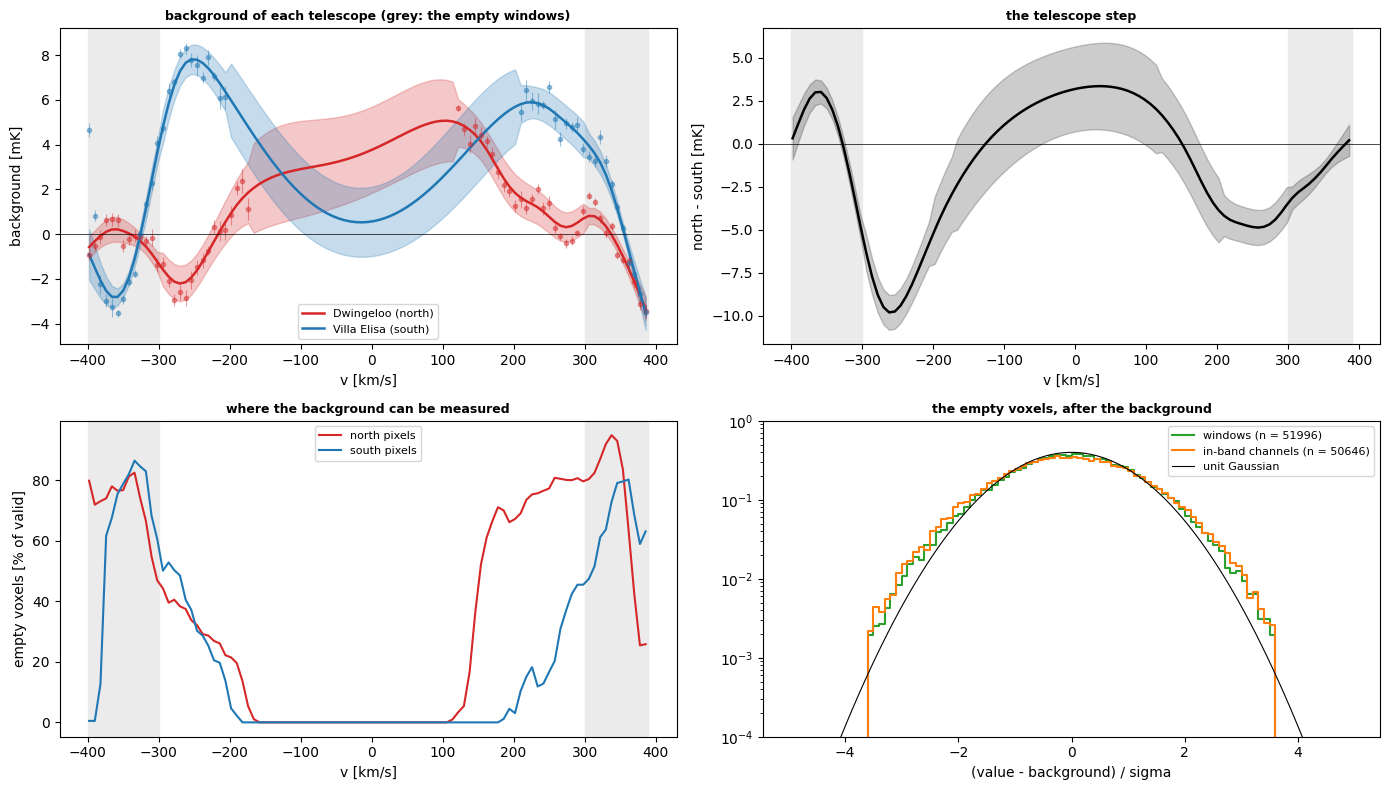

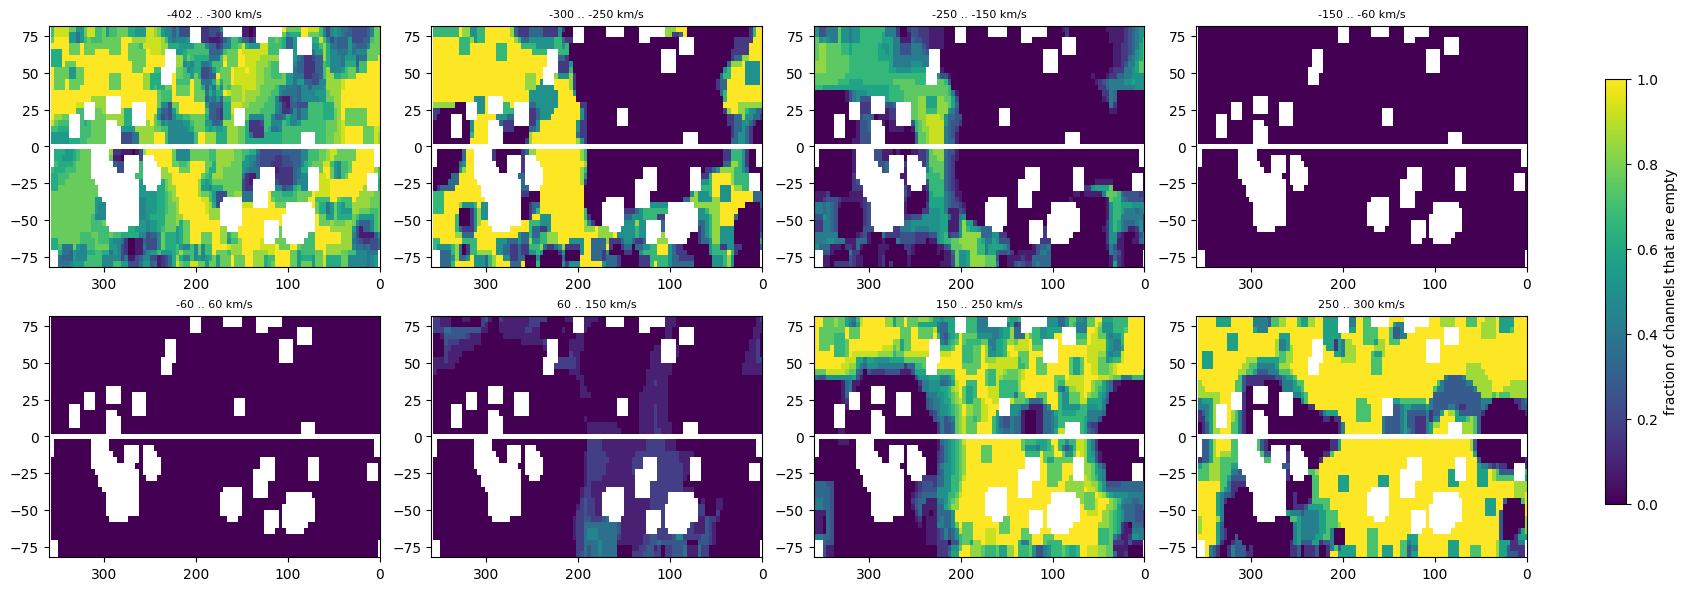

In [9]:
rows = bkg.group_stats(diag)
bkg.print_report(model, diag, rows)

in_band = ~bkg.in_ranges(model.v, NOISE_RANGES)
print(f"\nChannels measured: north {int(model.ok_north.sum())}, south {int(model.ok_south.sum())} of {len(model.v)} "
      f"(the rest is interpolated; in-band: north {int(model.ok_north[in_band].sum())}, "
      f"south {int(model.ok_south[in_band].sum())} of {int(in_band.sum())})")

print(f"Empty voxels: {100*diag['empty'].sum()/diag['valid'].sum():.0f} % of the valid ones; "
      f"profile errors (calibrated): windows {np.median(model.err_north[~in_band])*1e3:.2f}/"
      f"{np.median(model.err_south[~in_band])*1e3:.2f} mK, "
      f"in-band {np.median(model.err_north[in_band])*1e3:.2f}/"
      f"{np.median(model.err_south[in_band])*1e3:.2f} mK (north/south, median)")

print()
hyp = bkg.hypothesis_check(model, zo)

bkg.plot_background(model, diag)
plt.show()

bkg.plot_empty_map(diag)
plt.show()

### 5. Null test and closure test
* **Null test:** the cleaned empty channels laid over every channel (as in step 3) hold no emission and no background. The method must find a zero profile, and the kept fraction and the ratio $\sigma_\mathrm{kept}/\sigma_\mathrm{all}$ are the floor of the method (the two-sided cut removes the noise tails: ~0.8 in the tests).

* **Closure test:** known zero-level errors are *injected into the real cube* (the comparison pipeline is linear, so this is exact on the comparison grid) and recovered with the real emission and the real noise. 

`"Recovered minus injected"` is the bias and the scatter of the method **on LAB**. The injections exist only in the line channels (after `load_lab_clean` the windows are at zero): a plateau of +3/-3 mK, which is what the window step would become if the line channels did not share it, and a hump in $v$ (the case where the crowded centre limits us).

NULL (no emission, no background): recovered profile  max |c| = 3.94 mK  (rms north/south 0.58/2.26 mK)
       kept 64 % of the voxels;  sigma(all) 3.655 mK, sigma(kept) 2.894 mK, ratio 0.792;  mean of the kept voxels +0.027 mK
       tails of the null cube (mean over groups; Gauss 2.28 % at 2 sigma): tail+2 2.33%  tail-2 2.54%

CLOSURE, injected plateau +3 / -3 mK for |v| < 250 (the window offset is not in the line channels):
 recovered - injected [mK] | north rms   mean | south rms   mean | step rms   mean
                   windows |      0.12  -0.02 |      0.11  -0.02 |     0.23  +0.00
                   in-band |      1.09  -0.73 |      1.26  +0.89 |     2.31  -1.62
                   |v|<130 |      1.63  -1.58 |      1.82  +1.74 |     3.42  -3.31


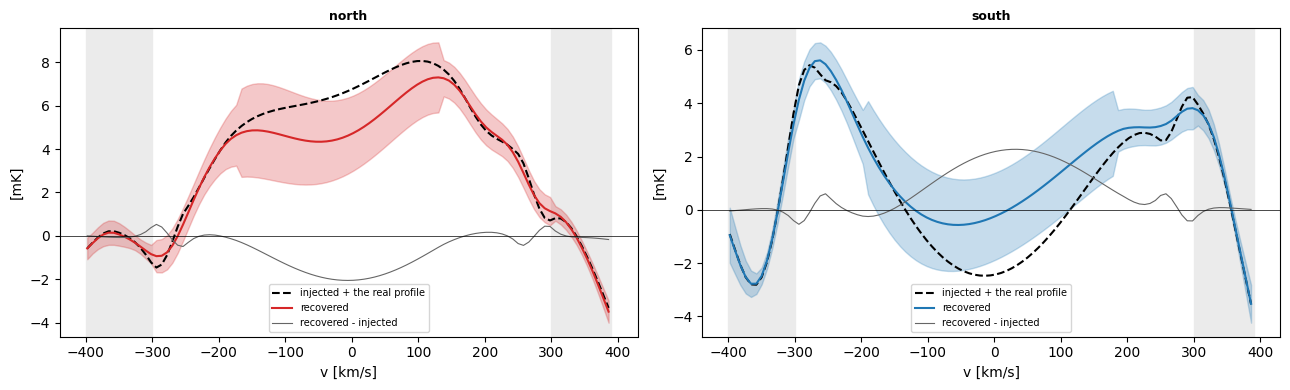


CLOSURE, injected hump +3 / -3 mK, sigma 90 km/s:
 recovered - injected [mK] | north rms   mean | south rms   mean | step rms   mean
                   windows |      0.00  -0.00 |      0.02  +0.01 |     0.02  -0.01
                   in-band |      1.31  -0.85 |      1.34  +0.88 |     2.64  -1.73
                   |v|<130 |      2.00  -1.88 |      2.02  +1.90 |     4.01  -3.79


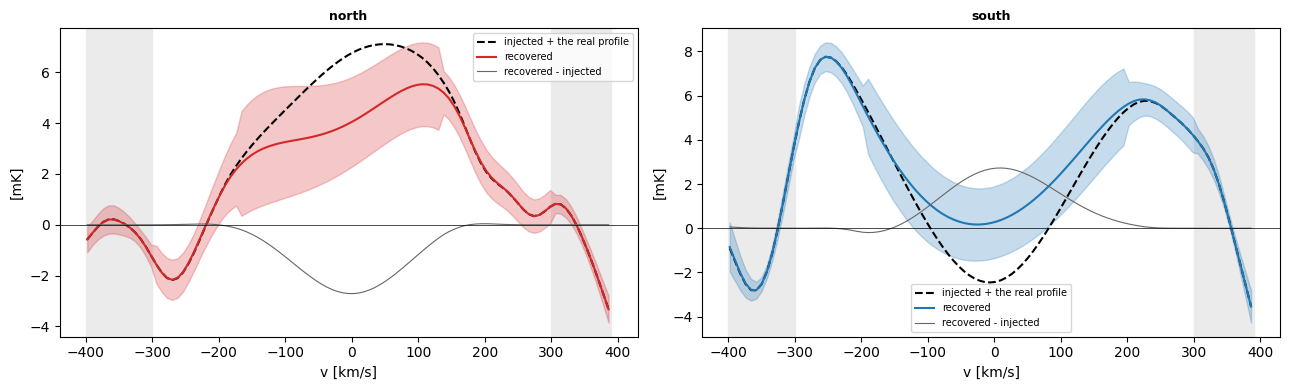

In [10]:
E_clean = E - np.median(E, axis=0)[None]
SIGMA_REF = SIGMA_EMPTY
null_ext = to_comparison_grid(bkg.OverlayCube(E_clean, len(v_lab), shift=0), ONES, ax_lab, cfg_ext, cfg.lab_beam_arcmin)
m_null, d_null, null_sum = bkg.null_check(null_ext, W_ext, SIGMA_REF, pixel_use=USE_CMP, finder=FINDER, **BG)

print(f"NULL (no emission, no background): recovered profile  max |c| = {null_sum['max_abs_profile_mK']:.2f} mK  "
      f"(rms north/south {np.sqrt(np.mean(m_null.north**2))*1e3:.2f}/{np.sqrt(np.mean(m_null.south**2))*1e3:.2f} mK)")
print(f"       kept {100*null_sum['kept_fraction']:.0f} % of the voxels;  sigma(all) {null_sum['sigma_all']*1e3:.3f} mK, "
      f"sigma(kept) {null_sum['sigma_empty']*1e3:.3f} mK, "
      f"ratio {null_sum['sigma_ratio']:.3f};  mean of the kept voxels {null_sum['mean_empty']*1e3:+.3f} mK")
rows_null = bkg.group_stats(d_null)
print("       tails of the null cube (mean over groups; Gauss 2.28 % at 2 sigma): "
      + "  ".join(f"{k} {100*np.nanmean([r.get(k, np.nan) for r in rows_null if r['zone']=='all']):.2f}%" \
                  for k in ("tail+2", "tail-2")))

# closure: errors that exist ONLY in the line channels (the windows are at zero after load_lab_clean).
def ramp(v, v0=250.0, v1=300.0):                      # 1 for |v| < v0, smoothly 0 beyond v1
    x = np.clip((np.abs(v) - v0) / (v1 - v0), 0.0, 1.0)
    return 1.0 - x * x * (3.0 - 2.0 * x)

cases = {"plateau +3 / -3 mK for |v| < 250 (the window offset is not in the line channels)": 
                                           (lambda v: 3e-3 * ramp(v), 
                                            lambda v: -3e-3 * ramp(v)),
         "hump +3 / -3 mK, sigma 90 km/s": (lambda v: 3e-3 * np.exp(-0.5 * (v / 90.0) ** 2), 
                                            lambda v: -3e-3 * np.exp(-0.5 * (v / 90.0) ** 2))}
for name, (fn, fs) in cases.items():
    print(f"\nCLOSURE, injected {name}:")
    m_inj, d_inj, c_n, c_s = bkg.closure_test(ext, W_ext, SIGMA_REF, fn, fs, 
                                              pixel_use=USE_CMP, finder=FINDER, w_native_args=DEC_ARGS, 
                                              verbose=False, **BG)
    
    bkg.closure_summary(model, m_inj, c_n, c_s)
    bkg.plot_closure(m_inj, c_n + model.north, c_s + model.south, n_label="injected + the real profile")
    plt.show()

### 6. Noise from the whole cube
The $\sigma$ of the compared voxels from the empty voxels of every channel, **after** the background, by velocity group and telescope, and by $|b|$. The two-sided finder cut shrinks the scatter of the kept voxels by the factor measured in the null test (`sigma_ratio`), which is divided out here. Compare the last column with the single `SIGMA` of step 2b: it is the check that the windows are representative of the line channels and of both telescopes.

In [11]:
tab = bkg.noise_table(diag, trunc_ratio=null_sum["sigma_ratio"])
bkg.print_noise_table(tab, sigma_ref=SIGMA_REF)

  v group [km/s] |      N      S    all |  voxels | all/ref
   -402..-300   |   4.11   2.60   3.65 |   28291 |   1.005
   -300..-250   |   4.20   2.63   3.66 |    7845 |   1.006
   -250..-150   |   3.89   2.84   3.65 |    6889 |   1.003
   -150..-60    |    nan    nan    nan |       0 |     nan
    -60..60     |    nan    nan    nan |       0 |     nan
     60..150    |   3.60    nan   3.59 |    1424 |   0.987
    150..250    |   3.99   2.51   3.91 |   19661 |   1.076
    250..300    |   3.93   2.58   3.70 |   14827 |   1.019
    300..390    |   3.66   2.66   3.37 |   23705 |   0.926
windows 3.522 mK    in-band 3.772 mK    (step 2b: 3.635 mK)
by |b| (in-band | windows) [mK]: 0-10: 3.72|3.51  10-20: 3.91|3.27  20-30: 3.65|3.34  30-45: 3.52|3.38  45-60: 3.67|3.50  60-80: 3.95|3.80


### 6b. Check, decide, apply
**The check:** In the windows, every voxel is empty, so the plain sky mean of a telescope's clean pixels *is* the background there. Subtracting the profile must leave that mean closer to zero than it found it, in both telescopes (`window_check`; the comparison is made on the cube as it is now, after the hot-pixel repair, so the two are on the same footing). A profile that fails this makes the windows worse, which is the opposite of the aim.

**The decision:** `APPLY_PROFILE = False` (default) keeps the cube of `load_lab_clean` (plus the hot-pixel repair if `REPAIR_HOT`). `True` subtracts the profile, but only if the check passed.

We do that only if we accept that faint line emission among the 'empty' voxels is subtracted with it (see the text of 3). The profile is first **shrunk towards zero where it is not significant** (`model.significant(SHRINK)`, $c \to c\,\max(0, 1-(\mathrm{SHRINK}\,\mathrm{err}/c)^2)$), so that a correction that is only noise does not add its estimation error to a cube that was already right.

In [12]:
APPLY_PROFILE = True    # True: subtract the profile of the two telescopes (only if the window check passes!).
SHRINK = 0.5            # Shrinkage threshold in units of the quoted error; 0 = the profile as measured

model_apply = model.significant(SHRINK)
W_CMP = W_ext.data[0]                               # the same in every channel
sm_pre = smoothed_noise_report(lab, ax_lab, cfg)    # the cube as it is now (hot-pixel repair done, profile not yet)

print(f"Profile that would be subtracted (shrunk, threshold {SHRINK:g} err): "
      f"max |c| north {np.abs(model_apply.north).max()*1e3:.2f} mK, "
      f"south {np.abs(model_apply.south).max()*1e3:.2f} mK  (measured: {np.abs(model.north).max()*1e3:.2f} "
      f"/ {np.abs(model.south).max()*1e3:.2f} mK)\n")

chk = bkg.window_check(model_apply, sm_pre, W_CMP, USE_CMP)

DO_PROFILE = bool(APPLY_PROFILE) and chk["ok"]
if APPLY_PROFILE and not chk["ok"]:
    print("\nAPPLY_PROFILE is True, but the window check FAILED: the profile is NOT applied.")
print(f"\nREPAIR_HOT = {REPAIR_HOT} (done in 3b).  Profile applied: {DO_PROFILE}")

if DO_PROFILE and not globals().get("BG_DONE", False):
    bkg.apply_background(lab, ax_lab, model_apply, w_north=W_NATIVE, inplace=True)
    BG_DONE = True

CORRECTION = ""
if REPAIR_HOT or DO_PROFILE:
    save_correction(CORR_PATH, model_apply if DO_PROFILE else None, HOT_EXCESS, DEC_ARGS)
    CORRECTION = CORR_PATH
    print(f"Correction stored in {CORR_PATH}" + (f" and {CORR_PATH}.model.npz" if DO_PROFILE else " (hot-pixel excess only)"))
else:
    print("No Correction: the cube is the one of load_lab_clean().")

Profile that would be subtracted (shrunk, threshold 0.5 err): max |c| north 4.91 mK, south 7.79 mK  (measured: 5.07 / 7.81 mK)

 window [km/s] | N before  N after | S before  S after   (plain sky mean of the clean pixels, mK)
  -400..-380   |    -0.91    -0.66 |     1.94     3.08
  -380..-340   |    -0.11    -0.11 |    -2.86    -0.34
  -340..-300   |     0.32     0.69 |     0.17    -0.19
   300..340    |     1.14     0.64 |     3.73     0.56
   340..380    |    -1.30     0.11 |    -0.41     0.08
   380..392    |    -1.34     1.81 |    -2.91     0.36
rms over the window channels, before -> after [mK]:  N 1.10 -> 0.86   S 2.68 -> 1.12;   max |after| N 1.81, S 4.46
   -> PASSED: the profile flattens the windows.

REPAIR_HOT = False (done in 3b).  Profile applied: True
Correction stored in lab_background_correction.npz and lab_background_correction.npz.model.npz


**Last check** (only if the profile was applied): the estimator run again on the corrected cube must find nothing left to remove.

Profile of the corrected cube: max |c| north 0.73 mK, south 0.84 mK; windows 0.73 / 0.64 mK


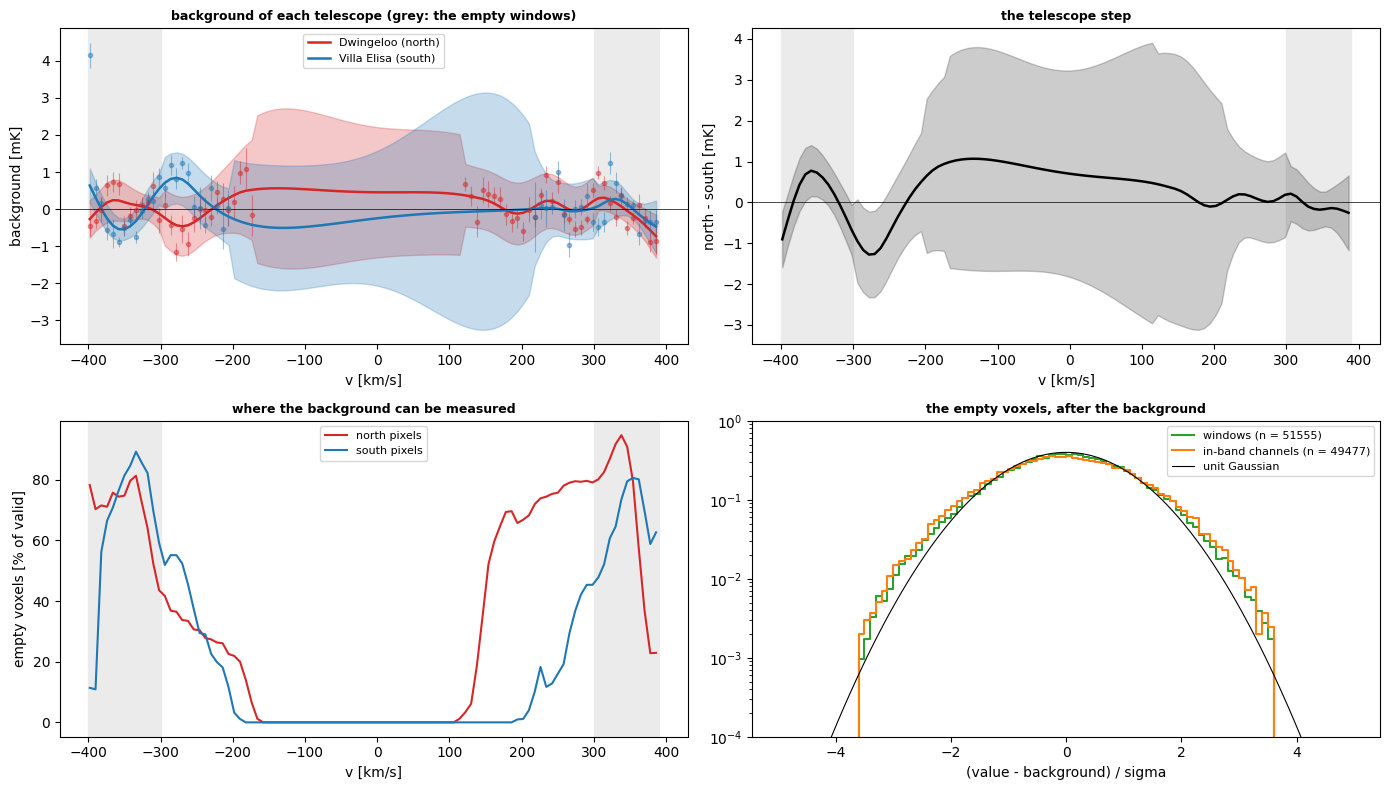

In [13]:
if globals().get("BG_DONE", False):
    cfg_ext2, ext2, W_ext2 = bkg.build_extended(lab, ONES, ax_lab, cfg, W_NATIVE)
    sm_bg = resummarize(smoothed_noise_report(lab, ax_lab, cfg), USE_CMP)
    model2, diag2 = bkg.estimate_background(ext2, W_ext2, sm_bg["sigma0"], 
                                            pixel_use=USE_CMP, finder=FINDER, verbose=False, **BG)
    
    print(f"Profile of the corrected cube: max |c| north {np.abs(model2.north).max()*1e3:.2f} mK, "
          f"south {np.abs(model2.south).max()*1e3:.2f} mK; "
          f"windows {np.abs(model2.north[~in_band]).max()*1e3:.2f} / {np.abs(model2.south[~in_band]).max()*1e3:.2f} mK")
    
    bkg.plot_background(model2, diag2)
    plt.show()
else:
    print("Profile not applied: nothing to check.")

## 7. The cube that will be loaded: sigma on it
From here on, `lab` is the cube that every other notebook will load. The noise of the empty channels (step 2), the clean pixels (2b) and the null test with the real keep mask are measured **on it**, so that sigma and cube belong together. If nothing was applied, this repeats steps 2-2b on the same cube (the numbers do not change).

In [14]:
sm_all = smoothed_noise_report(lab, ax_lab, cfg)
SIGMA_EMPTY_ALL = sm_all["sigma0"]
USE_CMP = np.ones(sm_all["S"].shape[1:], bool)
sm = sm_all
if USE_EXCLUSIONS:
    sm_x = sm_all
    for it in range(2):
        fl = emission_flags(sm_x, **FLAG)
        sm_x = resummarize(sm_all, fl["use"])
    USE_CMP, sm = fl["use"], sm_x
SIGMA_EMPTY = sm["sigma0"]

print(f"Flagged {fl['n_hot']} pixels, grown to {fl['n_grown']}. "
      f"Used {sm['n_pix_used']} of {sm['n_pix']} compared pixels" if USE_EXCLUSIONS else "all pixels used")
print(f"Sigma of the empty 8 km/s channels, clean pixels: {SIGMA_EMPTY*1e3:.3f} mK "
      f"(all pixels: {SIGMA_EMPTY_ALL*1e3:.3f} mK)")

Flagged 252 pixels, grown to 810. Used 2790 of 3600 compared pixels
Sigma of the empty 8 km/s channels, clean pixels: 3.123 mK (all pixels: 3.305 mK)


### LAB data and masks, on the final cube

In [15]:
def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

def load_model(name, folder):
    cube, l, b, v = load_npz(Path(folder) / f"{name}.npz")
    return cube, (l, b, v)

keep_lab = build_keep(lab, ax_lab)
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, cfg, rel_floor=REL_FLOOR)
print(f"Comparison grid: {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; "
      f"{int(np.isfinite(cmp.lab_cmp.data).sum())} LAB voxels with data")

Comparison grid: 62 channels x 41 b x 90 l; 163347 LAB voxels with data


## 8. Null test with the real mask
Everything above was measured without a mask. In the comparison, the normalized convolution averages only the kept voxels, so near mask edges the noise is higher than in the empty channels. Here the (offset-cleaned, native) empty channels are laid over the line channels (contiguous, so neighbouring channels stay correlated) and processed exactly like LAB, with the real keep mask. This gives **(a)** the sigma that applies to the compared voxels and **(b)** the fraction of voxels that exceed 2 and 3 sigma by chance, which is what the contours would show if the sky were empty.

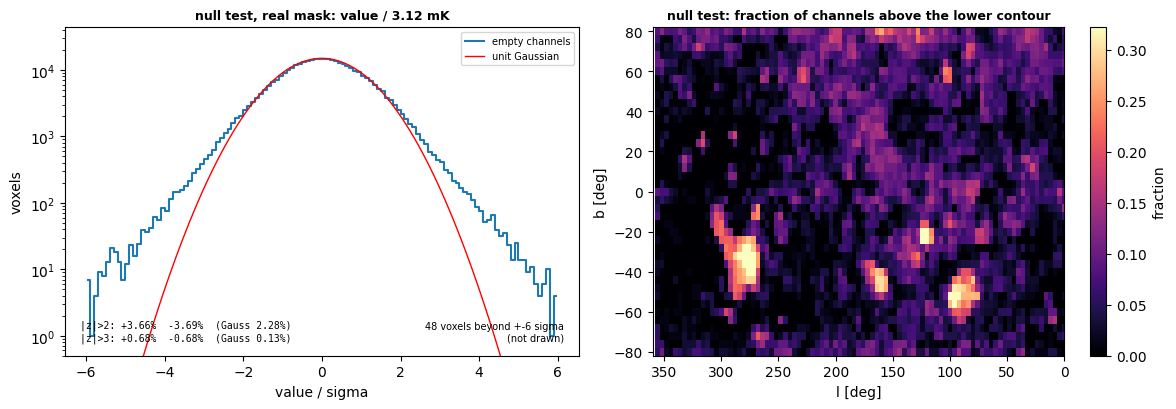

Sigma on the compared voxels (null test, 3 realisations): [3.28, 3.21, 3.23] mK;  empty channels without mask: 3.12 mK;  ratio 1.04
   beyond 2 sigma (sigma = 3.12 mK):  positive 3.663%   negative 3.687%   Gaussian 2.275% each
   beyond 3 sigma (sigma = 3.12 mK):  positive 0.684%   negative 0.675%   Gaussian 0.135% each


In [16]:
ref = np.zeros(len(v_lab), bool)
for lo, hi in NOISE_RANGES: ref |= (v_lab >= lo) & (v_lab <= hi)
E_final = lab[ref] # the empty channels of the FINAL cube.
E_clean = E_final - np.median(E_final, axis=0)[None]
valid_cmp = np.isfinite(cmp.lab_cmp.data) & (cmp.b != 0)[None, :, None] & USE_CMP[None]
# USE_CMP: the clean pixels of step 2b (every pixel if exclusions are off).

null = null_test(E_clean, keep_lab, ax_lab, cfg, valid_cmp, SIGMA_EMPTY, n_real=3, offset_map=None)
plot_null(null, SIGMA_EMPTY)
plt.show()

sig_null = float(np.mean([r["sigma_mad"] for r in null]))
print(f"Sigma on the compared voxels (null test, 3 realisations): "
      f"{[round(r['sigma_mad']*1e3, 2) for r in null]} mK;  "
      f"empty channels without mask: {SIGMA_EMPTY*1e3:.2f} mK;  ratio {sig_null/SIGMA_EMPTY:.2f}")

for k in null[0]["tails"]:
    print(f"   beyond {k:g} sigma (sigma = {SIGMA_EMPTY*1e3:.2f} mK):  "
          f"positive {100*np.mean([r['tails'][k]['pos'] for r in null]):.3f}%   "
          f"negative {100*np.mean([r['tails'][k]['neg'] for r in null]):.3f}%   "
          f"Gaussian {100*null[0]['tails'][k]['gauss']:.3f}% each")

### 8b. Which sigma?
* `"empty"`: the number from step 2 (original recipe). 
* `"null"`: the number from step 3, which includes the effect of the mask. 

If the two differ by more than ~20%, the second is the one that describes the compared voxels. We see that they have a ratio of ~1.02; therefore, we continue with `empty`.

The map version (sigma per pixel) is available too; set `SIGMA_MODE = "map"` to contour `data/sigma(l, b)` instead of data against one number. There doesn't seem to be need for it, though.

The choice is made in `sigma_contours.ipynb` (`SIGMA_SOURCE`, `SIGMA_MODE`); both numbers are stored here.

In [17]:
sig_null = float(np.mean([r["sigma_mad"] for r in null]))
sig_inband = tab["in_band"] if "tab" in globals() else np.nan
print(f"Sigma, empty channels: {SIGMA_EMPTY*1e3:.3f} mK;  "
      f"Null test: {sig_null*1e3:.3f} mK;  "
      f"In-band (4b, empty voxels of the line channels): {sig_inband*1e3:.3f} mK")

rows_ok = (cmp.b != 0)[:, None] & USE_CMP
W_c = W_ext.data[0]
sn = np.nanmedian(sm["sigma_map"][rows_ok & (W_c > 0.95)]); ss = np.nanmedian(sm["sigma_map"][rows_ok & (W_c < 0.05)])
print(f"Sigma Map (median per telescope): Dwingeloo {sn*1e3:.2f} mK, Villa Elisa {ss*1e3:.2f} mK  (ratio S/N {ss/sn:.2f}).\n"
      f"A single sigma treats the two alike: SIGMA_MODE = 'map' in sigma_contours does not.")

SAVE_NOTE = f"REPAIR_HOT={REPAIR_HOT} APPLY_PROFILE={APPLY_PROFILE} " + \
            f"profile_applied={globals().get('BG_DONE', False)} SHRINK={SHRINK}"

save_lab_products(PRODUCTS, lab, lab_path=LAB_PATH, sm=sm, sm_all=sm_all, sigma_empty=SIGMA_EMPTY, sigma_null=sig_null,
                  sigma_inband=sig_inband, use_cmp=USE_CMP, correction_path=CORRECTION, notes=SAVE_NOTE)

Sigma, empty channels: 3.123 mK;  Null test: 3.236 mK;  In-band (4b, empty voxels of the line channels): 3.772 mK
Sigma Map (median per telescope): Dwingeloo 3.14 mK, Villa Elisa 2.18 mK  (ratio S/N 0.69).
A single sigma treats the two alike: SIGMA_MODE = 'map' in sigma_contours does not.
Products stored in lab_products.npz: sigma = 3.123 mK (empty channels), 3.236 mK (null test); correction: lab_background_correction.npz.


### 8c. Final check

After everthing is saved, we load the saved products and repeat step 1 to see if our final product is appropriately working.

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: lab_background_correction.npz
Empty channels: 97 + 87 (native channel width 1.03 km/s)
Offset: median background over the sky +2.960e-01 mK, robust width 0.7 mK (mean-vs-median rms 14.5 mK)
Offset constant in v?  observed / expected width of (positive range - negative range) = 0.80   (1 = flat)
Sigma (median) per pixel, native: 71.7 mK
   The tail beyond 2 sigma:  positive 2.477%   negative 2.378%   Gaussian 2.275% each
   The tail beyond 3 sigma:  positive 0.227%   negative 0.174%   Gaussian 0.135% each


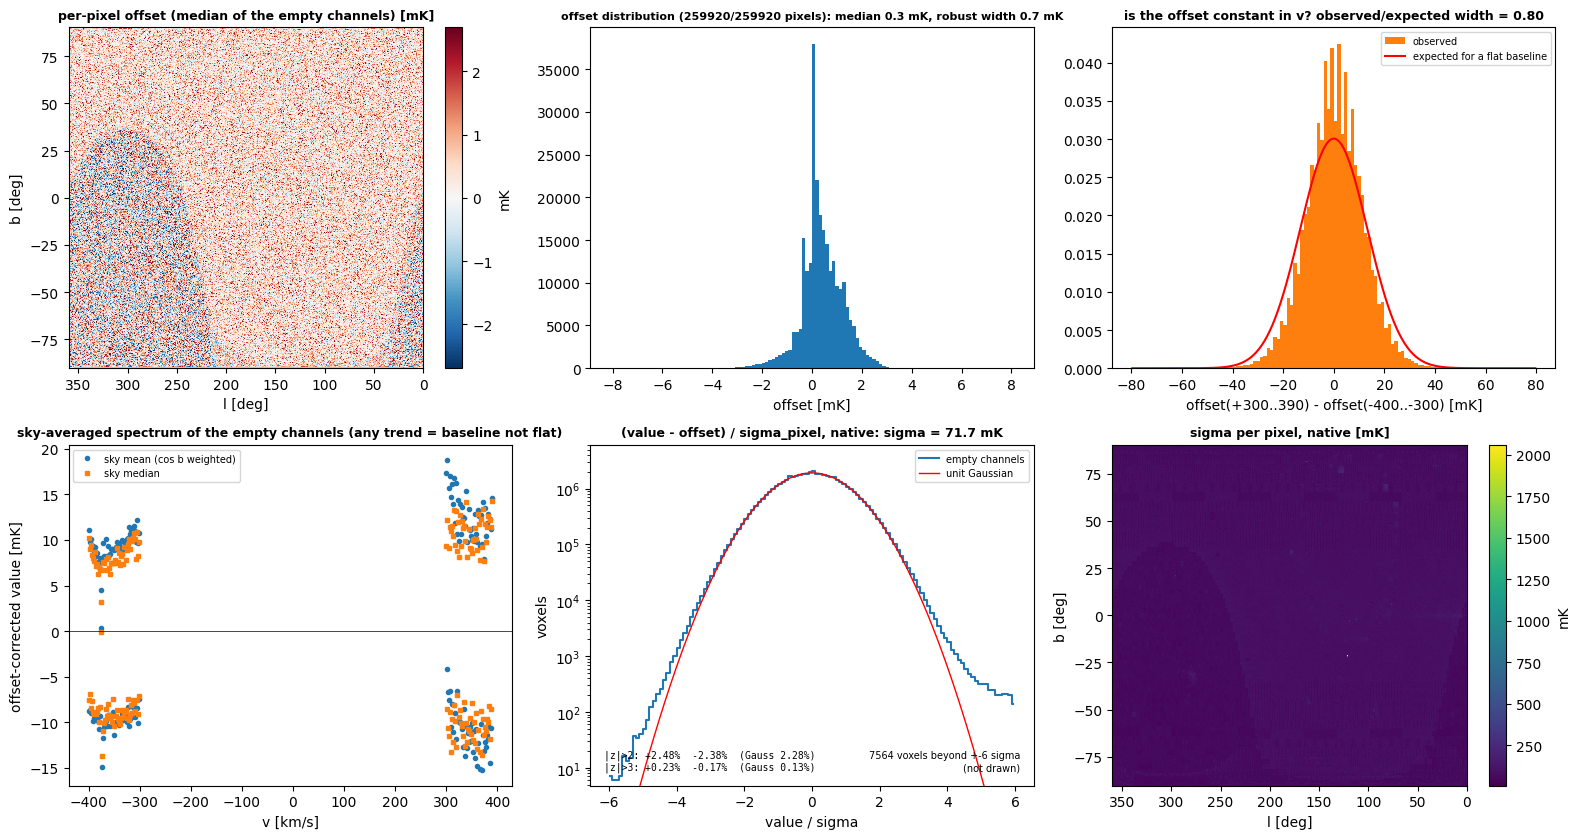

In [18]:
E_fin, l_e_fin, b_e_fin, v_e_fin = load_empty_channels(PRODUCTS, load_lab_products, NOISE_RANGES)
nat_fin = native_noise_report(E_fin, v_e_fin, l_e_fin, b_e_fin)

print(f"Empty channels: {nat_fin['n_per_range'][0]} + {nat_fin['n_per_range'][1]} "
      f"(native channel width {abs(np.median(np.diff(v_e_fin))):.2f} km/s)")
print(f"Offset: median background over the sky {nat_fin['offset_median']*1e3:+.3e} mK, "
      f"robust width {nat_fin['offset_rms']*1e3:.1f} mK (mean-vs-median rms {nat_fin['mean_minus_median_rms']*1e3:.1f} mK)")
print(f"Offset constant in v?  "
      f"observed / expected width of (positive range - negative range) = {nat_fin['baseline_excess']:.2f}   (1 = flat)")
print(f"Sigma (median) per pixel, native: {nat_fin['sigma_native']*1e3:.1f} mK")

for k, t in nat_fin["tails"].items():
    print(f"   The tail beyond {k:g} sigma:  positive {100*t['pos']:.3f}%   negative {100*t['neg']:.3f}%   "
          f"Gaussian {100*t['gauss']:.3f}% each")

plot_native_noise(nat_fin)
plt.show()

## What we learned?

* **Differences in telescopes:** By applying a profile subtraction (non-uniform in v), we were able to get the ±5 mK spread between LAB's two telescopes down to ±2 mK. 
* **Empty pixels:** By applying an iterative approach, we were able to get empty pixels beyond the empty windows without necessarily doing it by hand. With enough iterations, this has proven to be effective.
* **Remaining discrepancy:** The remaining noise behavior (which we see from the south-to-north ratio of ~0.7) is simply a behavior of the LAB survey and something that cannot be subtracted. We have reduced it here, however, the best way to get rid any little effect it might still have is to simply use another survey (like HI4PI) to double check our pipeline. Nothing more to do from that.